In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

# Set visualization style
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Load the cleaned dataset from GitHub
url = "https://raw.githubusercontent.com/anjaliumesh477/Python-Apprentice-Internship/main/Week-1-Data-Cleaning-EDA/telco_customer_churn_cleaned.csv"

df = pd.read_csv(url)

# Display dataset information
print("Dataset loaded successfully!")
print("Shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


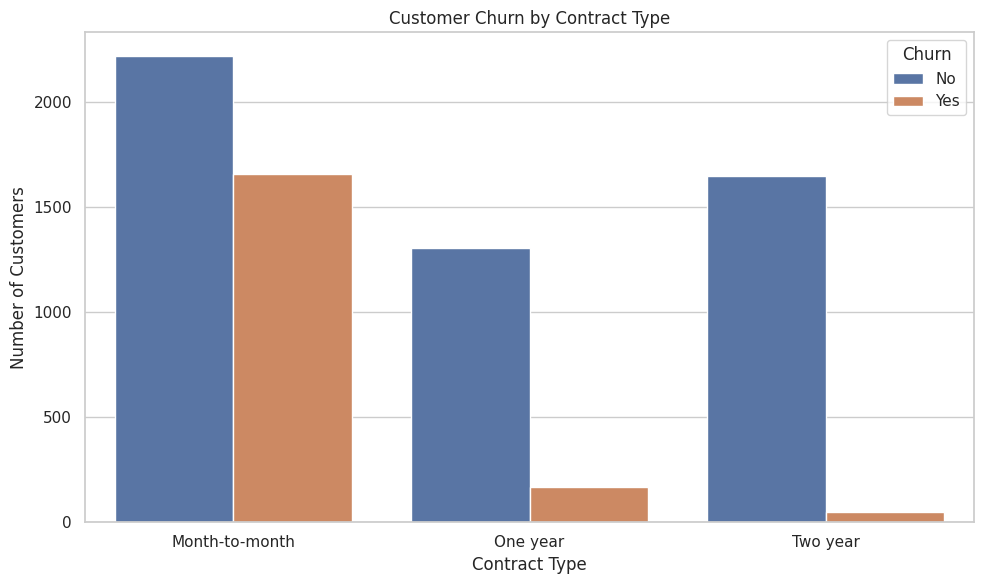

In [12]:
# Churn by Contract Type

plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    x="Contract",
    hue="Churn"
)

plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.legend(title="Churn")
plt.tight_layout()
plt.show()

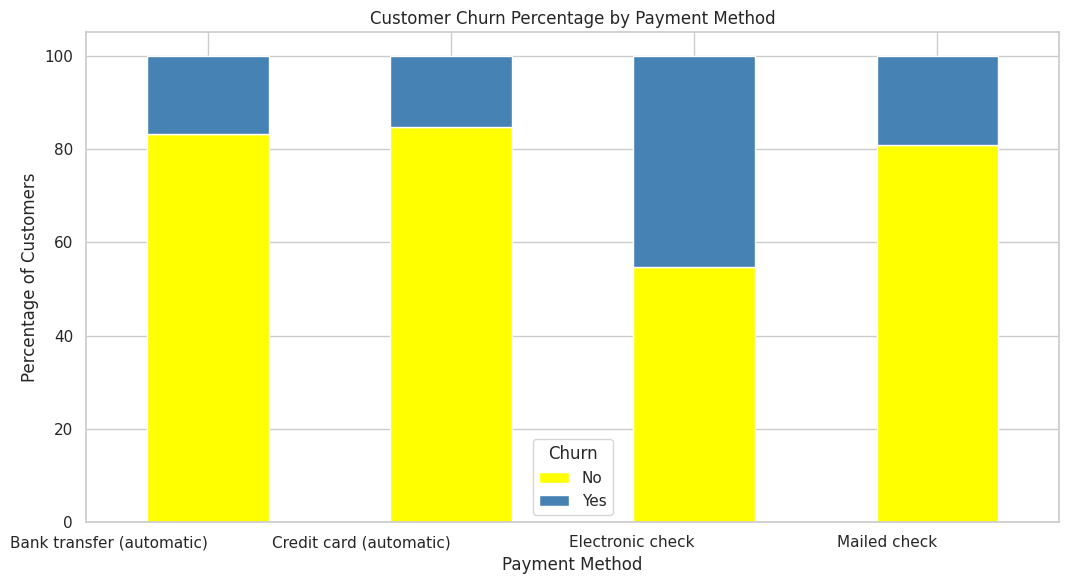

In [10]:
# Calculate churn percentages by payment method
payment_churn = pd.crosstab(
    df["PaymentMethod"],
    df["Churn"],
    normalize="index"
) * 100

# Create 100% stacked bar chart
payment_churn.plot(
    kind="bar",
    stacked=True,
    figsize=(11, 6),
    color=["yellow", "steelblue"]
)

plt.title("Customer Churn Percentage by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Percentage of Customers")
plt.legend(title="Churn")
plt.xticks(rotation=0, ha="right")
plt.tight_layout()
plt.show()

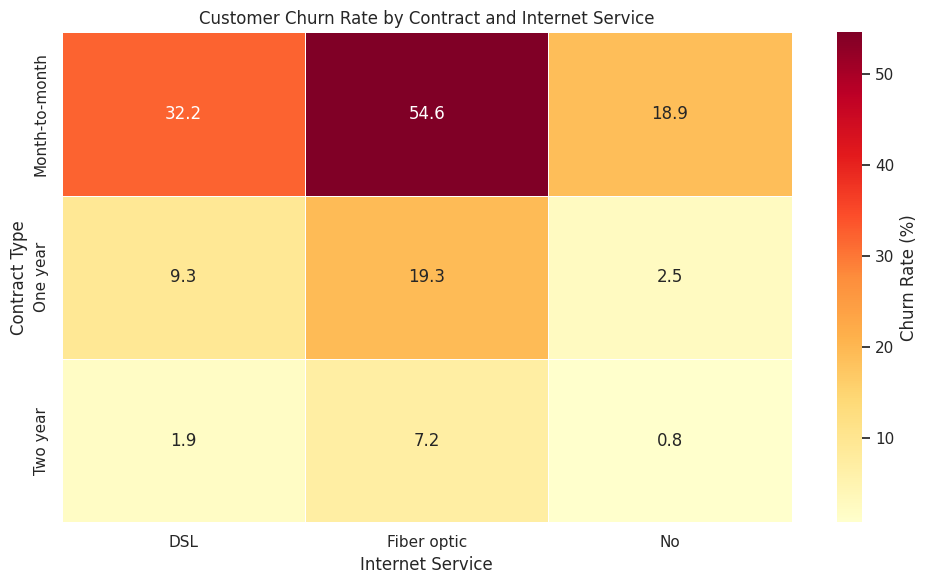

In [13]:
# Calculate churn rate by Contract and Internet Service
churn_data = df.copy()
churn_data["Churn_Flag"] = (churn_data["Churn"] == "Yes").astype(int)

churn_pivot = churn_data.pivot_table(
    values="Churn_Flag",
    index="Contract",
    columns="InternetService",
    aggfunc="mean"
) * 100

# Create heatmap
plt.figure(figsize=(10, 6))

sns.heatmap(
    churn_pivot,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    linewidths=0.5,
    cbar_kws={"label": "Churn Rate (%)"}
)

plt.title("Customer Churn Rate by Contract and Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Contract Type")
plt.tight_layout()
plt.show()

In [15]:
# Interactive Scatter Plot

fig = px.scatter(
    df,
    x="tenure",
    y="MonthlyCharges",
    color="Churn",
    hover_data=["Contract", "InternetService", "PaymentMethod"],
    title="Customer Tenure vs Monthly Charges",
    labels={
        "tenure": "Customer Tenure (Months)",
        "MonthlyCharges": "Monthly Charges ($)",
        "Churn": "Customer Churn"
    },
    color_discrete_map={
        "No": "steelblue",
        "Yes": "coral"
    },
    opacity=0.6
)

fig.update_layout(
    width=950,
    height=600
)

fig.show()

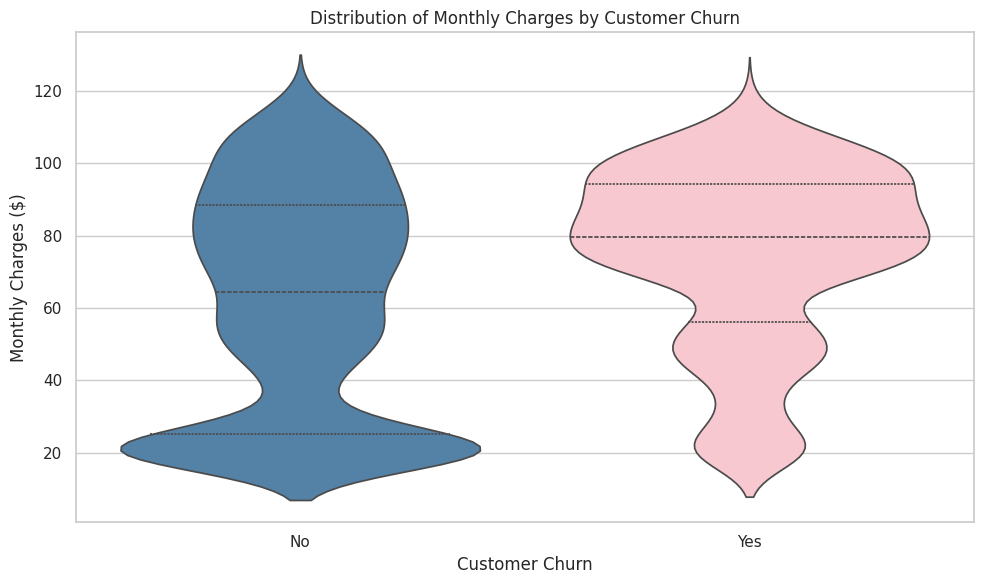

In [16]:
# Violin Plot: Monthly Charges by Churn

plt.figure(figsize=(10, 6))

sns.violinplot(
    data=df,
    x="Churn",
    y="MonthlyCharges",
    hue="Churn",
    palette=["steelblue", "pink"],
    inner="quartile",
    legend=False
)

plt.title("Distribution of Monthly Charges by Customer Churn")
plt.xlabel("Customer Churn")
plt.ylabel("Monthly Charges ($)")
plt.tight_layout()
plt.show()

In [17]:
# 1. Churn rate by contract type
print("CHURN RATE BY CONTRACT TYPE")
print(
    df.groupby("Contract")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .round(2)
)

# 2. Churn rate by payment method
print("\nCHURN RATE BY PAYMENT METHOD")
print(
    df.groupby("PaymentMethod")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .round(2)
)

# 3. Churn rate by contract and internet service
print("\nCHURN RATE BY CONTRACT AND INTERNET SERVICE")
print(
    df.assign(Churn_Flag=(df["Churn"] == "Yes").astype(int))
    .pivot_table(
        values="Churn_Flag",
        index="Contract",
        columns="InternetService",
        aggfunc="mean"
    ).mul(100).round(2)
)

# 4. Monthly charges by churn
print("\nMONTHLY CHARGES BY CHURN")
print(
    df.groupby("Churn")["MonthlyCharges"]
    .agg(["mean", "median"])
    .round(2)
)

# 5. Tenure by churn
print("\nAVERAGE TENURE BY CHURN")
print(
    df.groupby("Churn")["tenure"]
    .mean()
    .round(2)
)

CHURN RATE BY CONTRACT TYPE
Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Churn, dtype: float64

CHURN RATE BY PAYMENT METHOD
PaymentMethod
Bank transfer (automatic)    16.71
Credit card (automatic)      15.24
Electronic check             45.29
Mailed check                 19.11
Name: Churn, dtype: float64

CHURN RATE BY CONTRACT AND INTERNET SERVICE
InternetService    DSL  Fiber optic     No
Contract                                  
Month-to-month   32.22        54.61  18.89
One year          9.30        19.29   2.47
Two year          1.91         7.23   0.78

MONTHLY CHARGES BY CHURN
        mean  median
Churn               
No     61.27   64.43
Yes    74.44   79.65

AVERAGE TENURE BY CHURN
Churn
No     37.57
Yes    17.98
Name: tenure, dtype: float64
